# Average Daily Drug Dose

Quantify the reduction in average daily drug dose under AT

In [56]:
import os
import sys
import numpy as np
import pandas as pd
import scipy as sc
import matplotlib.pyplot as plt
from matplotlib.ticker import Locator, MaxNLocator
from matplotlib.colors import LogNorm, to_rgb, to_rgba
from matplotlib import colormaps
from tqdm import tqdm

sys.path.append("../utils")
from myUtils import calc_critical_treatment_threshold, calc_critical_treatment_interval
from plotUtils import PlotDrug, PlotSimulation, convert_to_rgb_grayscale
from odeModels import LotkaVolterraModel

In [13]:
# Defaults for plotting
plt.style.use(["classic", "../paper_figures/paper.mplstyle"])
plt.rcParams['font.size'] = '18'

colors = {'Sensitive': '#4c9150', 'Resistant': '#a80303', 'CT':'#c28d32' , 'AT':'#0044AA' ,'DRL_Monthly':'#66419e'}

/var/folders/by/xwl2vmrj5dl9941qxr6lr2t4002mml/T/ipykernel_81143/2301437773.py:10: UserWarning: FixedFormatter should only be used together with FixedLocator
  plt.gca().set_xticklabels([''] + list(colors.keys()));


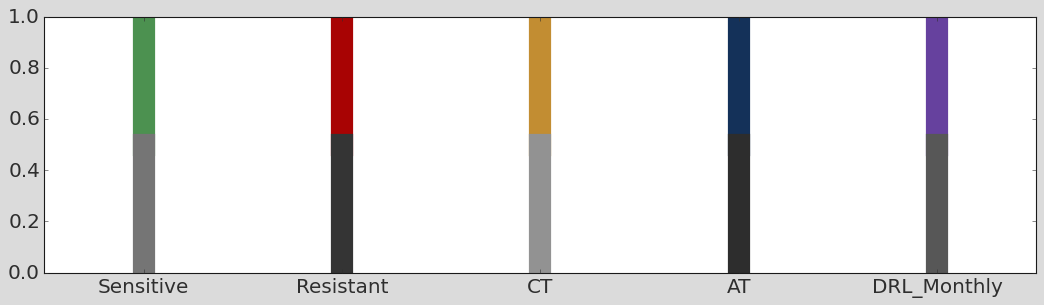

In [14]:
# Defaults for plotting
colors = {'Sensitive': '#4c9150', 'Resistant': '#a80303', 'CT':'#c28d32' , 'AT':'#0044AA' ,'DRL_Monthly':'#66419e'}

fig, ax = plt.subplots(1, 1, figsize=(16, 4))
for i, col in enumerate(colors.values()):
    plt.axvline(i+1, 0.5, 1, color = col, linewidth=20)
    plt.axvline(i+1, 0, 0.5, color = convert_to_rgb_grayscale(col), linewidth=20)
plt.xlim(0.5, len(colors.values()) + 0.5)
ax.xaxis.set_major_locator(MaxNLocator(integer=True))
plt.gca().set_xticklabels([''] + list(colors.keys()));

In [15]:
file_path = os.path.dirname(os.path.abspath("__file__"))

save_file = os.path.join("patient_fits", "drug_dose_records.csv")

## Patient Datasets

In [16]:
data_path = "../patients/Bruchovsky_et_al/Prog_data_txt"

# Load the data
df = pd.read_csv("patient_fits/full_history_params.csv")
trunc_df = pd.read_csv("patient_fits/first_cycle_params.csv")

patientIds = pd.merge(df[['PatientId']], trunc_df[['PatientId']], 
                      on='PatientId')['PatientId'].unique()

n = len(df['PatientId'].unique())
cols = [colormaps['tab10'](i/n) for i in range(n)]
markers = ['v', 's', 'X', 'P', 'o', '*', 'd',]

## Predicted benefit of Adaptive Therapy (TTP Calculations)

In [17]:
threshold_list = np.arange(0.0, 1.1, 0.1)

def calc_at_ttp(id, at_threshold=0.5):
    model = LotkaVolterraModel(method='RK45', dt=1)
    model.SetParams(**df[df['PatientId'] == id].iloc[0])
    return model.CalcTtp(threshold=at_threshold, updating_interval=1)

for threshold in tqdm(threshold_list):
    col_name = 'AT_Threshold_' + format(threshold, '.2f')
    if col_name not in df.columns.values:
        df[col_name] = df["PatientId"].apply(calc_at_ttp, args = [threshold])
df.to_csv(save_file)

100%|██████████| 11/11 [17:17<00:00, 94.29s/it]  


In [18]:
interval_list = np.arange(5, 185, 5)

def calc_best_ttp(id, interval):
    model = LotkaVolterraModel(dt=1); 
    params = df[df['PatientId'] == id].iloc[0]
    model.SetParams(**params)
    
    n_crit = calc_critical_treatment_threshold(tau = interval, **params)
    arg = n_crit/params['n0']

    model.Simulate_AT(atThreshold=arg, atMethod='Threshold',
                    intervalLength=interval, t_end=5000, refSize = params['n0'])
    model.resultsDf = model.resultsDf[model.resultsDf.TumourSize < 1.2 * params['n0']]

    return model.resultsDf.Time.max()

for interval in tqdm(interval_list):
    col_name = 'AT_OptThreshold_Interval_' + str(interval)
    if col_name not in df.columns.values:
        df[col_name] = df["PatientId"].apply(calc_best_ttp, args = [interval])
        
df.to_csv(save_file)

100%|██████████| 36/36 [16:51<00:00, 28.10s/it]  


## Drug Calculations for Perfect AT

In [19]:
threshold_list = np.arange(0.0, 1.05, 0.05)

def calc_at_drug(id, at_threshold=0.5):
    model = LotkaVolterraModel(method='RK45', dt=1)
    model.SetParams(**df[df['PatientId'] == id].iloc[0])
    model.Simulate_AT(atThreshold=at_threshold, intervalLength=1, t_end=5000)
    model.Trim(dt=1)
    return sum(model.resultsDf.DrugConcentration)

for threshold in tqdm(threshold_list):
    col_name = 'TotDrug_AT_Threshold_' + format(threshold, '.2f')
    if col_name not in df.columns.values:
        df[col_name] = df["PatientId"].apply(calc_at_drug, args = [threshold])
df.to_csv(save_file)

100%|██████████| 21/21 [16:57<00:00, 48.46s/it]  


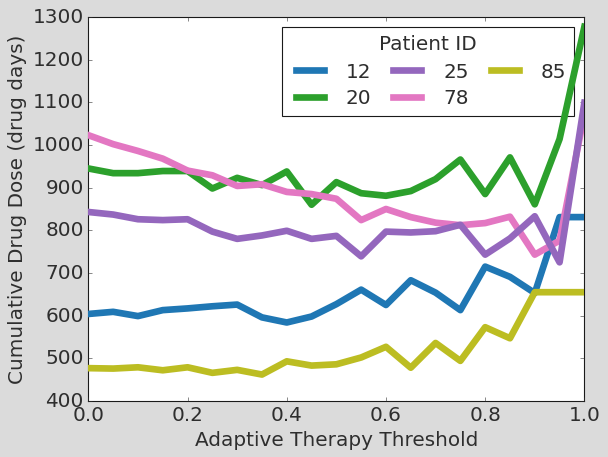

In [20]:
drug_col_names = ['TotDrug_AT_Threshold_' + format(num, '.2f') for num in threshold_list]

fig, ax = plt.subplots(figsize=(8, 6))
plt.rcParams['font.size'] = '18'

for n, id in enumerate(df['PatientId'].sort_values()):
    plt.plot([1-x for x in threshold_list], df.loc[df['PatientId'] == id, drug_col_names].values[0],
             linewidth=6, color=cols[n], label=id, zorder=(200 if id==25 else id))

plt.xlabel("Adaptive Therapy Threshold")
plt.ylabel("Cumulative Drug Dose (drug days)")
plt.legend(title="Patient ID", ncol=3, fontsize=18, title_fontsize=18, columnspacing=0.8,
           markerscale=1.5, loc=1, labelspacing=0.4, handlelength=2)
# plt.savefig("figures/bruchovsky/variable_at_interval_drug.pdf")
plt.show()

In [21]:
ttp_norm_threshold_col_names = ['AT_Threshold_' + format(num, '.2f') for num in threshold_list]
missing_cols = [col_name for col_name in ttp_norm_threshold_col_names 
                if col_name not in df.columns.values]

for col_name in tqdm(missing_cols):
    if col_name not in df.columns.values:
        threshold = float(col_name.split('_')[-1])
        # print(threshold)
        df[col_name] = df["PatientId"].apply(calc_at_ttp, args = [threshold])

df.to_csv(save_file)

100%|██████████| 10/10 [00:46<00:00,  4.60s/it]


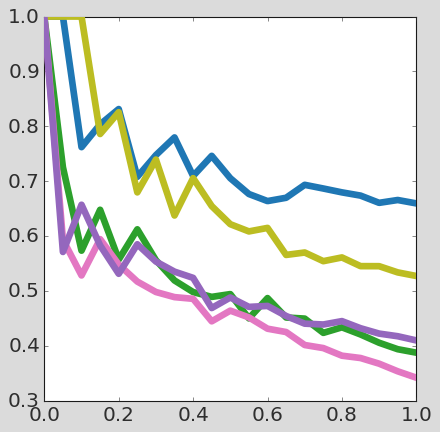

In [63]:
# Normalise by the TTP (so average drug concentration per day)

fig, ax = plt.subplots(figsize=(6, 6))
plt.rcParams['font.size'] = '18'

for n, id in enumerate(df['PatientId'].sort_values()):
    plt.plot([x for x in threshold_list], 
             (df.loc[df['PatientId'] == id, drug_col_names].values[0] 
              / df.loc[df['PatientId'] == id, ttp_norm_threshold_col_names].values[0]),
             linewidth=6, color=cols[n], label=id, zorder=(200 if id==25 else id))

# plt.xlabel("Adaptive Therapy Threshold"); plt.ylabel("Average Drug Dose (per day)")

# plt.legend(title="Patient ID", ncol=3, fontsize=18, title_fontsize=18, columnspacing=0.8,
#            markerscale=1.5, loc=1, labelspacing=0.4, handlelength=2).get_frame().set_boxstyle('Round', pad=0.2, rounding_size=0.5)
plt.savefig("figures/SI_variable_at_interval_drug.pdf")
plt.show()


## Drug calculations for Discrete AT

In [28]:
drug_interval_list = np.arange(5, 185, 5)
drug_interval_col_names = ['TotDrug_AT_OptThreshold_Interval_' + str(num) for num in drug_interval_list]

def calc_best_drug(id, interval):
    model = LotkaVolterraModel(dt=1); 
    params = df[df['PatientId'] == id].iloc[0] 
    model.SetParams(**params)
    
    n_crit = calc_critical_treatment_threshold(tau = interval, **params)
    arg = n_crit/params['n0']
    model.Simulate_AT(atThreshold=arg, atMethod='Threshold',
                    intervalLength=interval, t_end=5000, refSize = params['n0'])
    model.resultsDf = model.resultsDf[model.resultsDf.TumourSize < 1.2 * params['n0']]
    model.Trim()
    return sum(model.resultsDf.DrugConcentration)


for interval in tqdm(drug_interval_list):
    col_name = 'TotDrug_AT_OptThreshold_Interval_' + str(interval)
    if col_name not in df.columns.values:
        df[col_name] = df["PatientId"].apply(calc_best_drug, args = [interval])

df = df.copy()  # Fixes fragmented dataframe?
df.to_csv(save_file)
    

100%|██████████| 36/36 [00:00<00:00, 47230.20it/s]


In [27]:
ttp_norm_interval_col_names = ['AT_OptThreshold_Interval_' + format(num, '.2f') for num in drug_interval_list]
missing_cols = [col_name for col_name in ttp_norm_interval_col_names 
                if col_name not in df.columns.values]

for col_name in tqdm(missing_cols):
    interval = float(col_name.split('_')[-1])
    if col_name not in df.columns.values:
        df[col_name] = df["PatientId"].apply(calc_best_ttp, args = [interval])

100%|██████████| 36/36 [00:33<00:00,  1.07it/s]


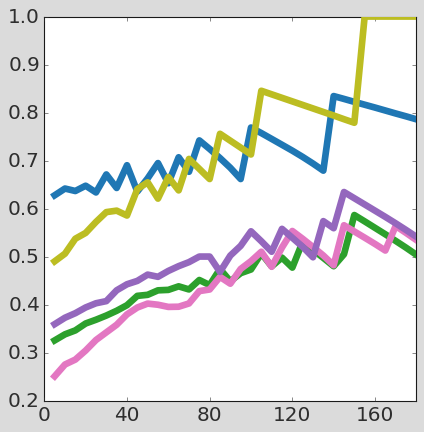

In [65]:
fig, ax = plt.subplots(figsize=(6, 6))
plt.rcParams['font.size'] = '18'

for n, id in enumerate(df['PatientId'].sort_values()):
    plt.plot([x for x in drug_interval_list], 
             (df.loc[df['PatientId'] == id, drug_interval_col_names].values[0]
              / df.loc[df['PatientId'] == id, ttp_norm_interval_col_names].values[0]),
             linewidth=6, color=cols[n], label=id, zorder=(200 if id==25 else id))
    
ax.set_xticks(ax.get_xticks()[::2])

# plt.xlabel("Treatment Decision Interval"); plt.ylabel("Average Drug Dose (per day)")
# plt.legend(title="Patient ID", ncol=2, fontsize=18, title_fontsize=18, columnspacing=0.8,
#            markerscale=1.5, loc=2, labelspacing=0.4, handlelength=2)
plt.savefig("figures/SI_variable_perfect_interval_drug.pdf")
plt.show()

## Results Space

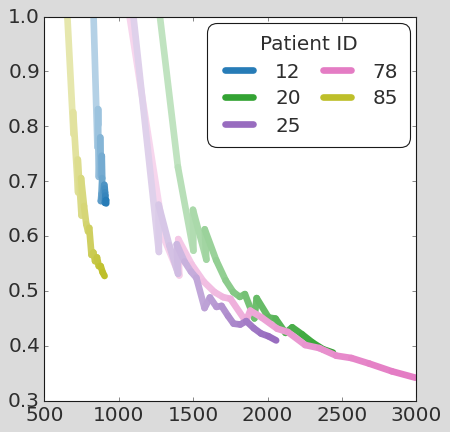

In [66]:
fig, ax = plt.subplots(figsize=(6, 6))
plt.rcParams['font.size'] = '18'

col_names = ['AT_Threshold_' + format(num, '.2f') for num in threshold_list]
min_color=0.3

def mix_with_white(color, mix_ratio):
    color = np.array(to_rgba(color, alpha=1.0)[:3])
    return color * (1 - mix_ratio) + np.array([1, 1, 1]) * mix_ratio

# Plot TTP against average drug for different treatment thresholds

for n, id in enumerate(df['PatientId'].sort_values()):
    ttp_values = df.loc[df['PatientId'] == id, col_names].values[0]
    drug_values = df.loc[df['PatientId'] == id, drug_col_names].values[0]
    ttp_norm_values = df.loc[df['PatientId'] == id, ttp_norm_threshold_col_names].values[0]
    avg_drug_values = drug_values / ttp_norm_values

    for i in range(len(threshold_list) - 1):
        color = mix_with_white(cols[n], 1 - (min_color + (1-min_color) * (threshold_list[i])))
        ax.plot(ttp_values[i:i+2], avg_drug_values[i:i+2], linewidth=6, color=color, 
                zorder=(100 if id == 25 else id)*0.01, solid_capstyle='round',
                label=id if i == len(threshold_list) - 2 else "")

# plt.xlabel("Time to Progression (days)"); plt.ylabel("Average Drug Dose (per day)")
plt.legend(title="Patient ID", ncol=2, fontsize=18, title_fontsize=18, columnspacing=0.8,
           markerscale=1.5, loc=1, labelspacing=0.4, handlelength=2).get_frame().set_boxstyle('Round', pad=0.2, rounding_size=0.5)
plt.savefig("figures/SI_results_space_ttp_drug.pdf")
plt.show()